In [1]:
import os
import sys
import time

import joblib
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.neighbors import LocalOutlierFactor

sys.path.insert(0, '../..') # Load Parent directory to import utils
from utils.helper_functions import normalize_series
from utils.metrics import show_feature_extraction_metrics
from utils.plotting import plot_movement_data
from utils.constants import Configs

/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


In [2]:
# Load the processed data from the csv
cache_path = Configs.ICATER_WRIST_ONLY_FILTERED_DATA_DIR
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [3]:
# Load the known outliers from the csv
outliers_csv = pd.read_csv(Configs.ICATER_OUTLIER_FILES).drop_duplicates(subset=['sub', 'repID'])
total_known_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
outliers_csv.head()

Total known outliers: 14


,sub,repID
0,2,2
1,4,1
2,5,2
3,5,5
4,7,1


In [ ]:
# LOAD INLIERS

target_movements = ['Pick', 'Place', 'Move']

inliers_dict = {}
for mov in target_movements:
    cache_path = Configs.cached_all_sensors_dtw_inliers('LOF', mov)
    
    if not os.path.exists(cache_path):
        raise FileNotFoundError(f"Ficheiro não encontrado para {mov} em {cache_path}. Verifica se já o geraste!")

    inliers_dict[mov] = joblib.load(cache_path)

df_inliers_pick = inliers_dict.get('Pick')
df_inliers_place = inliers_dict.get('Place')
df_inliers_move = inliers_dict.get('Move')

print("\n--- Resumo dos Dados Carregados ---")
if df_inliers_pick is not None: print(f"Linhas em Pick: {len(df_inliers_pick)}")
if df_inliers_place is not None: print(f"Linhas em Place: {len(df_inliers_place)}")
if df_inliers_move is not None: print(f"Linhas em Move: {len(df_inliers_move)}")


--- Resumo dos Dados Carregados ---
Linhas em Pick: 35287
Linhas em Place: 41133
Linhas em Move: 7816


--- Configuração do Gráfico para Move ---
Linhas de Inliers (Trajetórias Normais): 7816
Linhas de Outliers Detetados (Vão aparecer a Vermelho): 1279


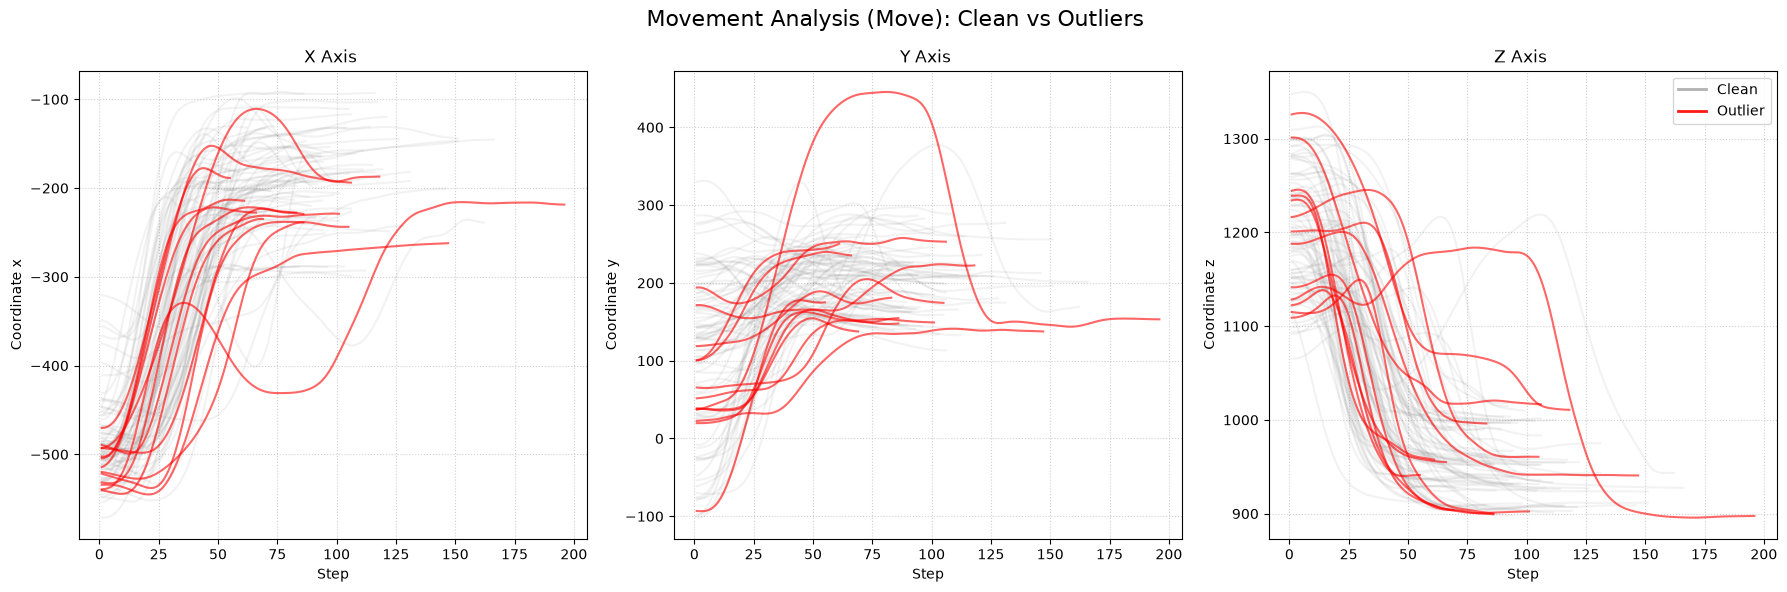

In [5]:
# ==========================================
# DIAGNÓSTICO E VISUALIZAÇÃO DE CONFIGURAÇÃO
# ==========================================

TARGET_MOV = 'Move'

# 2. Selecionar o DataFrame de inliers correto com base na tua escolha
if TARGET_MOV == 'Pick':
    inliers_temp = df_inliers_pick.copy()
elif TARGET_MOV == 'Move':
    inliers_temp = df_inliers_move.copy()
elif TARGET_MOV == 'Place':
    inliers_temp = df_inliers_place.copy()
else:
    inliers_temp = df_inliers_move.copy()

# Criar a chave 'temp_key' para agrupar as séries temporais nos inliers
inliers_temp['temp_key'] = inliers_temp['sub'].astype(str) + "_" + \
                           inliers_temp['repID'].astype(str) + "_" + \
                           inliers_temp['movID'].astype(str)

# 3. EXTRAIR OS OUTLIERS VERDADEIROS
# Vamos ao teu DataFrame original ('df' que carregou o filtered_data.csv completo)
df_original_mov = df[df['movLabel'] == TARGET_MOV].copy()

# Criar a mesma chave 'temp_key' no DataFrame original
df_original_mov['temp_key'] = df_original_mov['sub'].astype(str) + "_" + \
                              df_original_mov['repID'].astype(str) + "_" + \
                              df_original_mov['movID'].astype(str)

# Os outliers detetados são as linhas que estão no original mas NÃO estão nos inliers limpos
outliers_temp = df_original_mov[~df_original_mov['temp_key'].isin(inliers_temp['temp_key'])].copy()

print(f"--- Configuração do Gráfico para {TARGET_MOV} ---")
print(f"Linhas de Inliers (Trajetórias Normais): {len(inliers_temp)}")
print(f"Linhas de Outliers Detetados (Vão aparecer a Vermelho): {len(outliers_temp)}")

plot_movement_data(
    clean_data=inliers_temp,
    outlier_data=outliers_temp,  
    target_movement=TARGET_MOV,  
    axis_names=['x', 'y', 'z'] 
)

In [6]:
df_inliers_pick.head()

,sub,repID,movID,movType,step,movLabel,x,y,z,vel,acc,t,k,jerk
0,6,1,1,0,1,Pick,-187.534286,217.491546,910.599346,0.012873,0.021275,-0.172269,2.697837,0.000000
1,6,1,1,0,2,Pick,-187.742206,217.435138,910.603327,0.012939,0.039943,-0.465353,4.939217,0.018667
2,6,1,1,0,3,Pick,-187.957126,217.420031,910.602861,0.013292,0.074186,-1.444924,8.564583,0.034243
3,6,1,1,0,4,Pick,-188.185726,217.436719,910.601448,0.014188,0.103099,-3.299226,10.266306,0.028913
4,6,1,1,0,5,Pick,-188.434688,217.475693,910.602585,0.015738,0.125656,-6.755100,9.310180,0.022558


Export to csv

In [7]:
# 1. Juntar os 3 DataFrames num único
# Ignoramos os que possam ser None (caso algum ficheiro não tenha carregado)
dfs_to_concat = [df for df in [df_inliers_pick, df_inliers_place, df_inliers_move] if df is not None]
df_all_inliers = pd.concat(dfs_to_concat, ignore_index=True)

# 3. Filtrar APENAS as colunas que pediste
colunas_pedidas = ['sub', 'repID', 'movID', 'movType', 'step', 'x', 'y', 'z', 'vel', 'acc', 't', 'k']

# Garantir que usamos apenas as colunas disponíveis (evita erros se alguma variável faltar)
colunas_finais = [col for col in colunas_pedidas if col in df_all_inliers.columns]
df_final = df_all_inliers[colunas_finais].copy()

# Opcional, mas muito recomendado: Ordenar os dados cronologicamente
# Garante que dentro de cada ficheiro os movimentos e os steps aparecem pela ordem correta
df_final = df_final.sort_values(by=['sub', 'repID', 'movID', 'step']).reset_index(drop=True)


output_dir = Configs.WRIST_ONLY_FINAL_INLIERS
os.makedirs(output_dir, exist_ok=True)

# 5. Separar por Subject e exportar para CSV
subjects_unicos = df_final['sub'].unique()

print(f"A iniciar a exportação para {len(subjects_unicos)} sujeitos...\n")

for subject in subjects_unicos:
    df_subject = df_final[df_final['sub'] == subject]
    
    # Criar o nome do ficheiro (ex: Subject1Tasks.csv)
    # Usa-se int() para garantir que não fica Subject1.0Tasks.csv
    filename = f"Subject{int(subject)}Tasks.csv"
    filepath = os.path.join(output_dir, filename)
    
    df_subject.to_csv(filepath, index=False)
    print(f"Guardado: {filename} com {len(df_subject)} linhas.")

print(f"\n✅ Todos os {len(subjects_unicos)} ficheiros foram gerados com sucesso na pasta: {output_dir}")

A iniciar a exportação para 19 sujeitos...

Guardado: Subject1Tasks.csv com 5960 linhas.
Guardado: Subject2Tasks.csv com 5372 linhas.
Guardado: Subject3Tasks.csv com 4544 linhas.
Guardado: Subject4Tasks.csv com 2887 linhas.
Guardado: Subject5Tasks.csv com 4279 linhas.
Guardado: Subject6Tasks.csv com 5523 linhas.
Guardado: Subject7Tasks.csv com 3928 linhas.
Guardado: Subject8Tasks.csv com 5303 linhas.
Guardado: Subject9Tasks.csv com 3789 linhas.
Guardado: Subject10Tasks.csv com 4088 linhas.
Guardado: Subject11Tasks.csv com 4079 linhas.
Guardado: Subject12Tasks.csv com 3526 linhas.
Guardado: Subject13Tasks.csv com 4920 linhas.
Guardado: Subject14Tasks.csv com 2963 linhas.
Guardado: Subject15Tasks.csv com 4113 linhas.
Guardado: Subject16Tasks.csv com 4368 linhas.
Guardado: Subject17Tasks.csv com 4851 linhas.
Guardado: Subject18Tasks.csv com 4844 linhas.
Guardado: Subject19Tasks.csv com 4899 linhas.

✅ Todos os 19 ficheiros foram gerados com sucesso na pasta: /home/hugo-guimar-es/Documents